In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score,
    calinski_harabasz_score, adjusted_rand_score
)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

In [4]:
DATA_PATH = Path("../outputs/customer_segments.csv")
OUTPUT_DIR = Path("../outputs/model_3_rfm_clv_without_monetary")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ID_COL = "CustomerID"
FEATURE_COLS = ["Recency", "Frequency", "PredictiveCLV"]
PROFILE_COLS = ["Recency", "Frequency", "Monetary", "PredictiveCLV"]

K_VALUES = range(2, 11)
FINAL_K = 3
RANDOM_STATE = 42
N_INIT = 10
STABILITY_SEEDS = [11, 21, 42, 52, 62]

LOG_FEATURES = ["Frequency", "PredictiveCLV"]

In [5]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"File tidak ditemukan: {DATA_PATH.resolve()}. Periksa DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)
print("Ukuran data:", df.shape)
print("Kolom:", df.columns.tolist())
display(df.head())

Ukuran data: (4338, 11)
Kolom: ['CustomerID', 'LastPurchaseDate', 'Recency', 'Frequency', 'Monetary', 'ExpectedPurchases', 'ExpectedAOV', 'PredictiveCLV', 'ImputedPrediction', 'Cluster', 'ProfileLabel']


,CustomerID,LastPurchaseDate,Recency,Frequency,Monetary,ExpectedPurchases,ExpectedAOV,PredictiveCLV,ImputedPrediction,Cluster,ProfileLabel
0,12346,2011-01-18 10:01:00,326,1,"77,183.6000",0.1500,377.6331,55.5392,False,0,At Risk
1,12347,2011-12-07 15:52:00,2,7,"4,310.0000",1.4481,553.1129,785.2325,False,2,High Value / Loyal
2,12348,2011-09-25 13:13:00,75,4,"1,797.2400",0.8074,327.8919,259.5204,False,1,Potential
3,12349,2011-11-21 09:51:00,19,1,"1,757.5500",1.2566,377.6331,463.8261,True,1,Potential
4,12350,2011-02-02 16:01:00,310,1,334.4000,0.1565,377.6331,57.9237,False,0,At Risk


In [6]:
required_cols = [ID_COL, "Recency", "Frequency", "Monetary", "PredictiveCLV"]
missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    raise ValueError(f"Kolom belum ditemukan: {missing_cols}")

data = df[required_cols].copy()

for col in required_cols[1:]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

print("Missing values:")
display(data.isna().sum().to_frame("Missing"))

data = data.dropna(subset=required_cols).copy()

if data[ID_COL].duplicated().any():
    raise ValueError("CustomerID duplikat. Pastikan satu baris mewakili satu pelanggan.")

for col in FEATURE_COLS:
    if (data[col] < 0).any():
        raise ValueError(f"{col} memiliki nilai negatif; periksa data sebelum log1p.")

if any(data[c].nunique() <= 1 for c in FEATURE_COLS):
    raise ValueError("Ada fitur clustering yang konstan/tidak memiliki variasi.")

data = data.reset_index(drop=True)
print("Jumlah pelanggan:", len(data))
display(data[required_cols].describe().T)

Missing values:


,Missing
CustomerID,0
Recency,0
Frequency,0
Monetary,0
PredictiveCLV,0


Jumlah pelanggan: 4338


,count,mean,std,min,25%,50%,75%,max
CustomerID,"4,338.0000","15,300.4080","1,721.8085","12,346.0000","13,813.2500","15,299.5000","16,778.7500","18,287.0000"
Recency,"4,338.0000",92.5364,100.0142,1.0000,18.0000,51.0000,142.0000,374.0000
Frequency,"4,338.0000",4.2720,7.6980,1.0000,1.0000,2.0000,5.0000,209.0000
Monetary,"4,338.0000","2,048.6922","8,985.2297",3.7500,306.4825,668.5700,"1,660.5975","280,206.0200"
PredictiveCLV,"4,338.0000",535.1079,"1,953.9780",0.0000,132.8911,252.5265,472.8560,"61,381.0427"


,count,mean,std,min,25%,50%,75%,max
Recency,"4,338.0000",92.5364,100.0142,1.0000,18.0000,51.0000,142.0000,374.0000
Frequency,"4,338.0000",4.2720,7.6980,1.0000,1.0000,2.0000,5.0000,209.0000
PredictiveCLV,"4,338.0000",535.1079,"1,953.9780",0.0000,132.8911,252.5265,472.8560,"61,381.0427"


,Skewness
Recency,1.2460
Frequency,12.0670
PredictiveCLV,19.1847


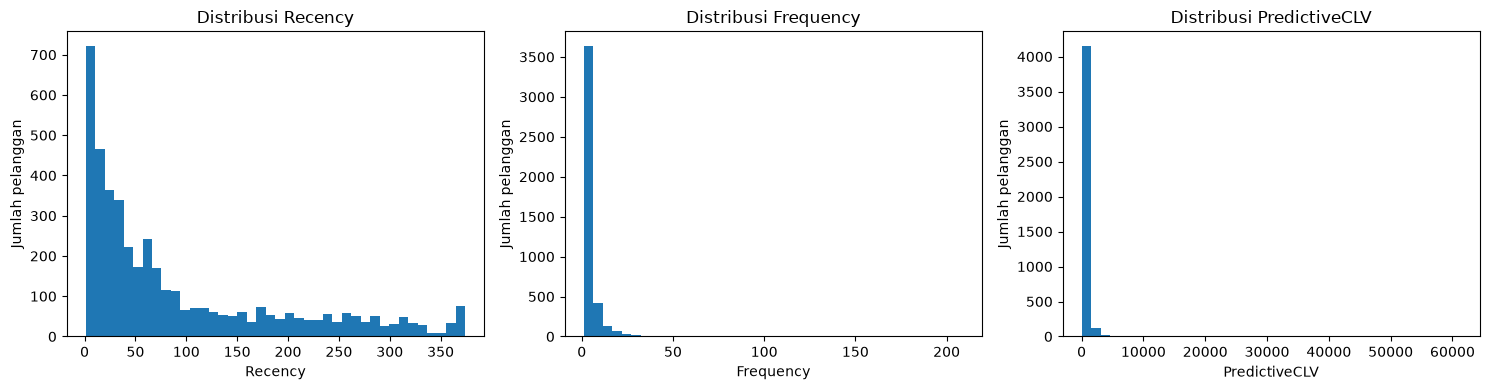

In [7]:
display(data[FEATURE_COLS].describe().T)
display(data[FEATURE_COLS].skew().to_frame("Skewness"))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, FEATURE_COLS):
    ax.hist(data[col], bins=40)
    ax.set_title(f"Distribusi {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Jumlah pelanggan")
plt.tight_layout()
plt.show()

In [8]:
X_transformed = data[FEATURE_COLS].copy()

for col in LOG_FEATURES:
    if col in X_transformed.columns:
        X_transformed[col] = np.log1p(X_transformed[col])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_transformed)

print("Fitur yang masuk K-Means:", FEATURE_COLS)
display(pd.DataFrame(X_scaled, columns=FEATURE_COLS).describe().T)

Fitur yang masuk K-Means: ['Recency', 'Frequency', 'PredictiveCLV']


,count,mean,std,min,25%,50%,75%,max
Recency,"4,338.0000",0.0000,1.0001,-0.9153,-0.7453,-0.4154,0.4946,2.8146
Frequency,"4,338.0000",-0.0000,1.0001,-0.9552,-0.9552,-0.3616,0.6532,5.8585
PredictiveCLV,"4,338.0000",-0.0000,1.0001,-5.6311,-0.6928,-0.0489,0.5818,5.4867


In [9]:
metrics_rows = []

for k in K_VALUES:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT)
    labels = model.fit_predict(X_scaled)

    metrics_rows.append({
        "K": k,
        "Silhouette": silhouette_score(X_scaled, labels),
        "DBI": davies_bouldin_score(X_scaled, labels),
        "CHI": calinski_harabasz_score(X_scaled, labels),
        "Inertia": model.inertia_
    })

metrics_df = pd.DataFrame(metrics_rows)
display(metrics_df.round(4))
metrics_df.to_csv(OUTPUT_DIR / "model_3_evaluation_metrics.csv", index=False)

,K,Silhouette,DBI,CHI,Inertia
0,2,0.4394,0.8092,"3,977.9052","6,787.2681"
1,3,0.4502,0.7664,"5,406.4274","3,724.3754"
2,4,0.4029,0.8468,"5,195.0492","2,831.5844"
3,5,0.3794,0.8609,"4,909.0324","2,352.5953"
4,6,0.3575,0.9245,"4,783.7794","1,995.5702"
5,7,0.3606,0.9166,"4,572.5207","1,774.3484"
6,8,0.3379,0.9775,"4,410.5094","1,600.7807"
7,9,0.3425,0.9419,"4,336.0793","1,443.9024"
8,10,0.3485,0.9289,"4,278.4272","1,314.9743"


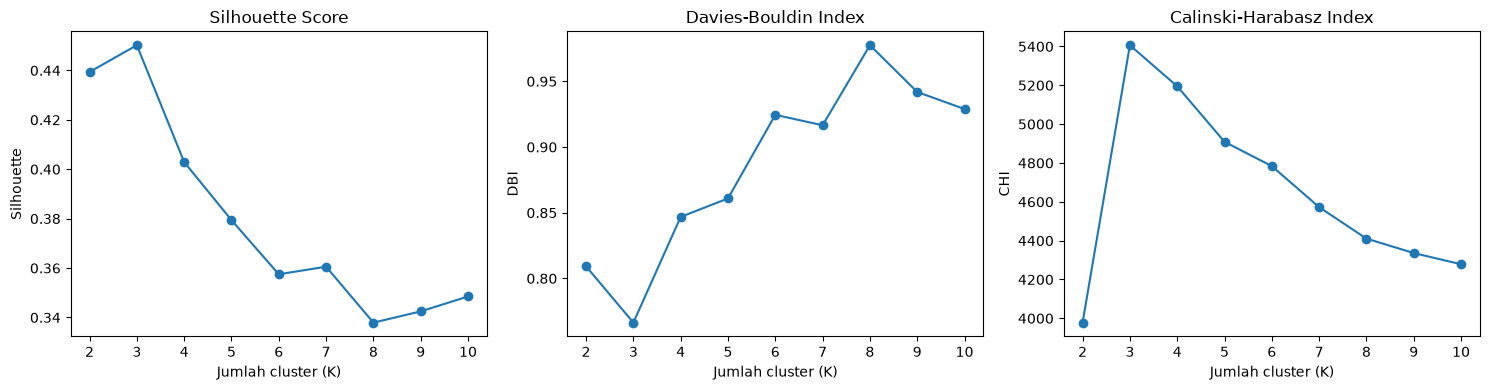

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plots = [
    ("Silhouette", "Silhouette Score"),
    ("DBI", "Davies-Bouldin Index"),
    ("CHI", "Calinski-Harabasz Index")
]
for ax, (col, title) in zip(axes, plots):
    ax.plot(metrics_df["K"], metrics_df[col], marker="o")
    ax.set_title(title)
    ax.set_xlabel("Jumlah cluster (K)")
    ax.set_ylabel(col)
plt.tight_layout()
plt.show()

In [11]:
final_model = KMeans(
    n_clusters=FINAL_K, random_state=RANDOM_STATE, n_init=N_INIT
)
data["Cluster_Model_3"] = final_model.fit_predict(X_scaled)

display(
    data["Cluster_Model_3"].value_counts().sort_index()
    .rename("NumCustomers").to_frame()
)

,NumCustomers
Cluster_Model_3,
0,2246
1,1016
2,1076


In [12]:
profile = data.groupby("Cluster_Model_3").agg(
    NumCustomers=(ID_COL, "count"),
    AvgRecency=("Recency", "mean"),
    MedianRecency=("Recency", "median"),
    AvgFrequency=("Frequency", "mean"),
    MedianFrequency=("Frequency", "median"),
    AvgMonetary=("Monetary", "mean"),
    MedianMonetary=("Monetary", "median"),
    AvgPredictiveCLV=("PredictiveCLV", "mean"),
    MedianPredictiveCLV=("PredictiveCLV", "median"),
    TotalMonetary=("Monetary", "sum"),
    TotalPredictiveCLV=("PredictiveCLV", "sum")
).reset_index()

profile["PctCustomers"] = profile["NumCustomers"] / len(data) * 100
display(profile.round(2))
profile.to_csv(OUTPUT_DIR / "model_3_cluster_profile.csv", index=False)

,Cluster_Model_3,NumCustomers,AvgRecency,MedianRecency,AvgFrequency,MedianFrequency,AvgMonetary,MedianMonetary,AvgPredictiveCLV,MedianPredictiveCLV,TotalMonetary,TotalPredictiveCLV,PctCustomers
0,0,2246,54.1300,45.0000,2.3300,2.0000,754.4700,588.9200,285.1400,248.0500,"1,694,532.8000","640,424.4100",51.7800
1,1,1016,251.2500,247.5000,1.3900,1.0000,488.7700,300.2300,85.4000,74.2000,"496,591.7500","86,766.8400",23.4200
2,2,1076,22.8400,13.0000,11.0400,8.0000,"6,223.1400","2,881.4000","1,481.5100",777.6400,"6,696,102.3400","1,594,106.8300",24.8000


In [13]:
seed_labels = {}

for seed in STABILITY_SEEDS:
    model = KMeans(n_clusters=FINAL_K, random_state=seed, n_init=N_INIT)
    seed_labels[seed] = model.fit_predict(X_scaled)

stability_rows = []
seeds = list(seed_labels.keys())

for i in range(len(seeds)):
    for j in range(i + 1, len(seeds)):
        s1, s2 = seeds[i], seeds[j]
        stability_rows.append({
            "Seed_1": s1,
            "Seed_2": s2,
            "ARI": adjusted_rand_score(seed_labels[s1], seed_labels[s2])
        })

stability_df = pd.DataFrame(stability_rows)
display(stability_df.round(4))
print("Mean ARI:", round(stability_df["ARI"].mean(), 4))
print("Minimum ARI:", round(stability_df["ARI"].min(), 4))
stability_df.to_csv(OUTPUT_DIR / "model_3_stability_ari.csv", index=False)

,Seed_1,Seed_2,ARI
0,11,21,0.9647
1,11,42,0.9852
2,11,52,0.9926
3,11,62,0.9926
4,21,42,0.9793
5,21,52,0.9575
6,21,62,0.9706
7,42,52,0.9778
8,42,62,0.9911
9,52,62,0.9852


Mean ARI: 0.9796
Minimum ARI: 0.9575


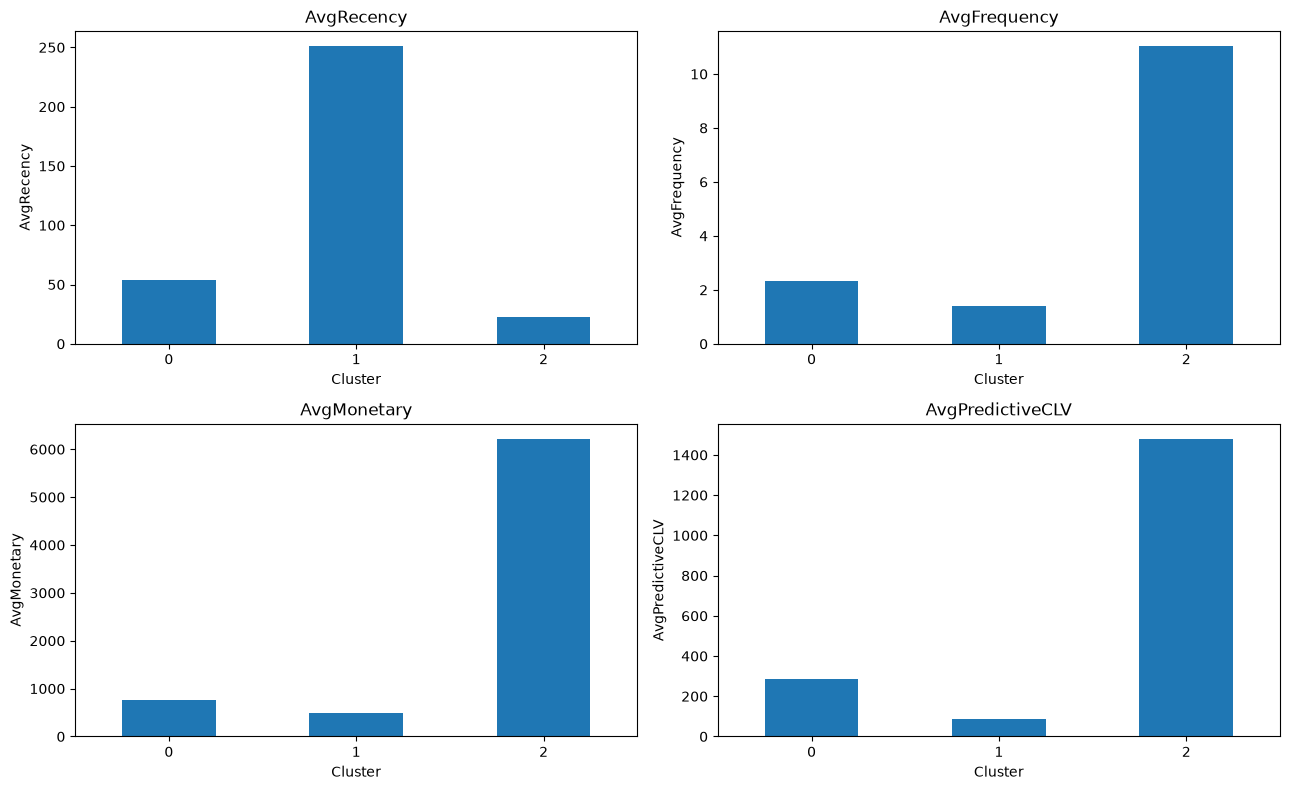

In [14]:
profile_plot = profile.set_index("Cluster_Model_3")[
    ["AvgRecency", "AvgFrequency", "AvgMonetary", "AvgPredictiveCLV"]
]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.flatten(), profile_plot.columns):
    profile_plot[col].plot(kind="bar", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Cluster")
    ax.set_ylabel(col)
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

In [15]:
data.to_csv(OUTPUT_DIR / "model_3_customer_clusters.csv", index=False)

print("Hasil tersimpan di:", OUTPUT_DIR.resolve())
for file in sorted(OUTPUT_DIR.glob("*.csv")):
    print("-", file.name)

Hasil tersimpan di: D:\UNUD\Semester 5\Machine Learning\project clustering\customer-segmentation\outputs\model_3_rfm_clv_without_monetary
- model_3_cluster_profile.csv
- model_3_customer_clusters.csv
- model_3_evaluation_metrics.csv
- model_3_stability_ari.csv


In [16]:
print("Jumlah data:", len(df))
print("Jumlah CustomerID unik:", df["CustomerID"].nunique())

print("\nMissing values:")
print(df[["CustomerID", "Recency", "Frequency",
          "Monetary", "PredictiveCLV"]].isnull().sum())

print("\nStatistik fitur:")
display(df[["Recency", "Frequency",
            "Monetary", "PredictiveCLV"]].describe())

Jumlah data: 4338
Jumlah CustomerID unik: 4338

Missing values:
CustomerID       0
Recency          0
Frequency        0
Monetary         0
PredictiveCLV    0
dtype: int64

Statistik fitur:


,Recency,Frequency,Monetary,PredictiveCLV
count,"4,338.0000","4,338.0000","4,338.0000","4,338.0000"
mean,92.5364,4.2720,"2,048.6922",535.1079
std,100.0142,7.6980,"8,985.2297","1,953.9780"
min,1.0000,1.0000,3.7500,0.0000
25%,18.0000,1.0000,306.4825,132.8911
50%,51.0000,2.0000,668.5700,252.5265
75%,142.0000,5.0000,"1,660.5975",472.8560
max,374.0000,209.0000,"280,206.0200","61,381.0427"
